In [1]:
import json
import polars as pl
import matplotlib.pyplot as plt

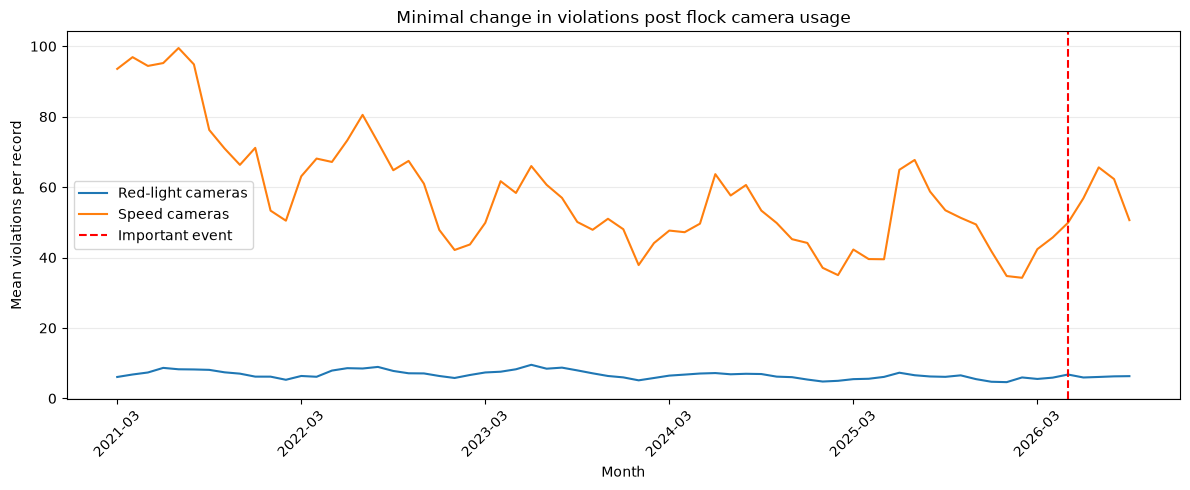

Red-light lowest: ('2026-01', 4.611635220125786) highest: ('2023-06', 9.534458509142054)
Speed-camera lowest: ('2026-02', 34.24656679151061) highest: ('2021-07', 99.4894451145959)


In [13]:
red_light = pl.read_csv("../red_light_100000.csv", schema_overrides={"VIOLATIONS": pl.String}).select(
    pl.col("VIOLATION DATE")
    .str.strptime(pl.Date, "%m/%d/%Y", strict=False)
    .dt.strftime("%Y-%m")
    .alias("month"),
    pl.col("VIOLATIONS").str.replace_all(",", "").cast(pl.Float64, strict=False).alias("violations"),
).drop_nulls().filter(pl.col("month") >= "2021-03").group_by("month").agg(pl.col("violations").mean().alias("mean_violations")).sort("month")

speed_camera = pl.read_csv("../updatedSpeed.csv", schema_overrides={"VIOLATIONS": pl.String}).select(
    pl.col("VIOLATION DATE")
    .str.strptime(pl.Date, "%m/%d/%Y", strict=False)
    .dt.strftime("%Y-%m")
    .alias("month"),
    pl.col("VIOLATIONS").str.replace_all(",", "").cast(pl.Float64, strict=False).alias("violations"),
).drop_nulls().filter(pl.col("month") >= "2021-03").group_by("month").agg(pl.col("violations").mean().alias("mean_violations")).sort("month")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(red_light["month"], red_light["mean_violations"], label="Red-light cameras")
ax.plot(speed_camera["month"], speed_camera["mean_violations"], label="Speed cameras")
ax.set(title="Minimal change in violations post flock camera usage", xlabel="Month", ylabel="Mean violations per record")
ax.tick_params(axis="x", labelrotation=45)
ax.set_xticks(ax.get_xticks()[::12])
ax.grid(axis="y", alpha=0.25)
ax.axvline("2026-05", color="red", linestyle="--", linewidth=1.5, label="Important event")
ax.legend()
fig.tight_layout()
plt.show()

for label, monthly_data in [("Red-light", red_light), ("Speed-camera", speed_camera)]:
    print(label, "lowest:", monthly_data.sort("mean_violations").row(0), "highest:", monthly_data.sort("mean_violations", descending=True).row(0))